# Yoga Pose Dataset — Complete Description & Analysis

**Dataset:** Custom yoga posture image collection  
**Total Images:** 2,756  |  **Classes:** 47  |  **Total Size:** ~468 MB  

This notebook provides a thorough exploratory data analysis (EDA) of the yoga dataset:
1. Class distribution (count per pose)
2. Imbalance analysis
3. Image format & colour mode breakdown
4. Resolution / aspect-ratio analysis
5. File size distribution
6. Sample image grid per class
7. Dataset summary statistics table


In [1]:
import os, json, glob, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
from collections import Counter

plt.rcParams.update({
    'figure.facecolor': '#0f0f23',
    'axes.facecolor':   '#1a1a2e',
    'axes.edgecolor':   '#444',
    'axes.labelcolor':  'white',
    'xtick.color':      'white',
    'ytick.color':      'white',
    'text.color':       'white',
    'grid.color':       '#333',
    'grid.alpha':       0.5,
})

DATASET_DIR = r'd:\Yoga Website\Dataset'
VALID_EXT   = {'.jpg', '.jpeg', '.png'}

# ── Scan dataset ──────────────────────────────────────────────────────────────
records = []
for cls in sorted(os.listdir(DATASET_DIR)):
    cls_dir = os.path.join(DATASET_DIR, cls)
    if not os.path.isdir(cls_dir): continue
    for fname in os.listdir(cls_dir):
        ext = os.path.splitext(fname)[1].lower()
        if ext not in VALID_EXT: continue
        fpath = os.path.join(cls_dir, fname)
        sz    = os.path.getsize(fpath)
        try:
            with Image.open(fpath) as img:
                w, h, mode = img.width, img.height, img.mode
        except:
            w, h, mode = 0, 0, 'unknown'
        records.append({'class': cls, 'path': fpath, 'ext': ext,
                        'size_kb': sz/1024, 'width': w, 'height': h,
                        'mode': mode, 'aspect': round(w/h,2) if h else 0})

df = pd.DataFrame(records)
classes = sorted(df['class'].unique())
NUM_CLASSES = len(classes)
print(f'Total images : {len(df)}')
print(f'Classes      : {NUM_CLASSES}')
print(f'Total size   : {df.size_kb.sum()/1024:.1f} MB')
print(f'\nFirst 5 rows:')
display(df.head())


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\ABHIROOP\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


Total images : 2756
Classes      : 47
Total size   : 468.5 MB

First 5 rows:


,class,path,ext,size_kb,width,height,mode,aspect
0,Adho Mukha Svanasana,d:\Yoga Website\Dataset\Adho Mukha Svanasana\F...,.png,153.701172,748,382,RGBA,1.96
1,Adho Mukha Svanasana,d:\Yoga Website\Dataset\Adho Mukha Svanasana\F...,.png,156.445312,478,354,RGBA,1.35
2,Adho Mukha Svanasana,d:\Yoga Website\Dataset\Adho Mukha Svanasana\F...,.png,184.953125,663,562,RGBA,1.18
3,Adho Mukha Svanasana,d:\Yoga Website\Dataset\Adho Mukha Svanasana\F...,.png,168.198242,413,300,RGBA,1.38
4,Adho Mukha Svanasana,d:\Yoga Website\Dataset\Adho Mukha Svanasana\F...,.png,58.501953,846,476,RGB,1.78


## 1. Summary Statistics Table


In [2]:
summary = df.groupby('class').agg(
    Count      = ('path',    'count'),
    Avg_KB     = ('size_kb', 'mean'),
    Avg_Width  = ('width',   'mean'),
    Avg_Height = ('height',  'mean'),
    Avg_Aspect = ('aspect',  'mean'),
).round(1)
summary.index.name = 'Pose Class'
summary.columns = ['Count', 'Avg Size (KB)', 'Avg Width (px)', 'Avg Height (px)', 'Avg Aspect Ratio']
summary_sorted = summary.sort_values('Count', ascending=False)
print(f'Min count: {summary["Count"].min()} ({summary["Count"].idxmin()})')
print(f'Max count: {summary["Count"].max()} ({summary["Count"].idxmax()})')
print(f'Mean count: {summary["Count"].mean():.1f}')
print(f'Std  count: {summary["Count"].std():.1f}')
display(summary_sorted.style.background_gradient(cmap='Blues', subset=['Count']))


Min count: 12 (Ashta Chandrasana)
Max count: 96 (Ardha Matsyendrasana)
Mean count: 58.6
Std  count: 24.0


,Count,Avg Size (KB),Avg Width (px),Avg Height (px),Avg Aspect Ratio
Pose Class,,,,,
Ardha Matsyendrasana,96,155.100000,346.700000,354.100000,1.000000
Ustrasana,96,133.800000,287.800000,339.500000,0.900000
Bitilasana,94,117.100000,404.900000,279.500000,1.500000
Garudasana,85,102.800000,171.600000,443.600000,0.400000
Bakasana,84,155.400000,352.500000,325.500000,1.100000
Utkatasana,81,133.500000,342.200000,488.200000,0.700000
Baddha Konasana,81,234.300000,481.100000,380.100000,1.300000
Vasisthasana,80,180.400000,422.800000,378.200000,1.200000
Balasana,79,158.400000,545.900000,267.000000,2.200000


## 2. Class Distribution — Images per Pose


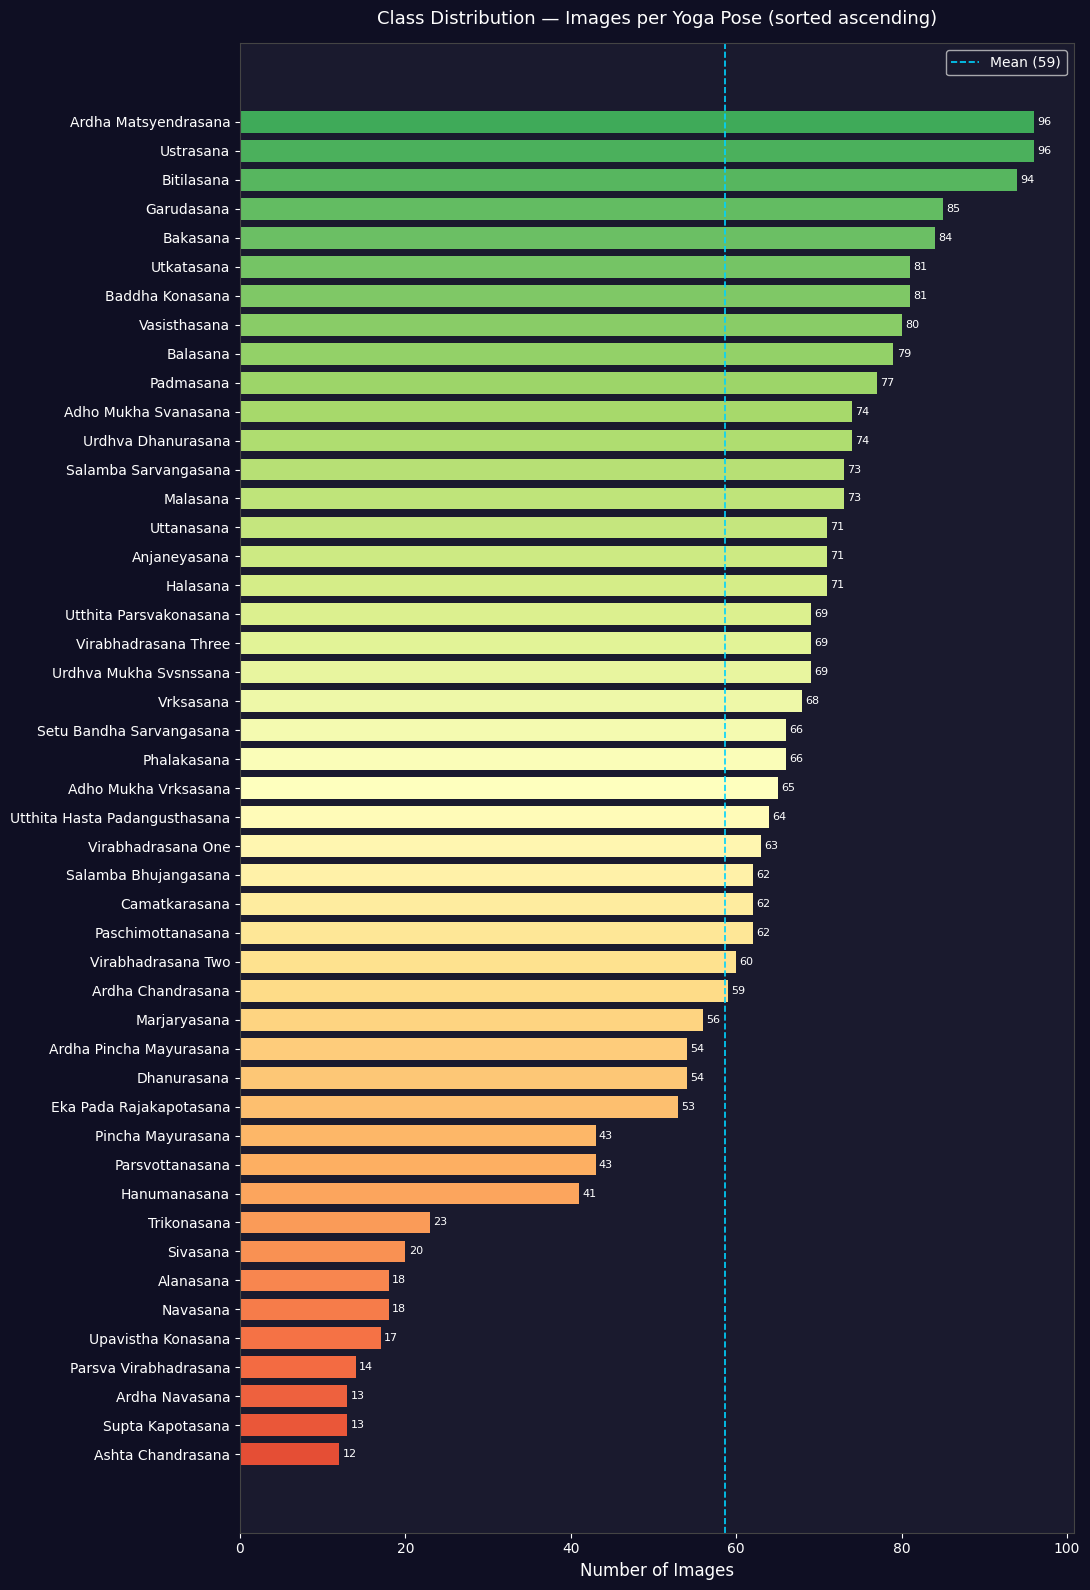

In [3]:
counts = df.groupby('class').size().sort_values(ascending=True)
colors = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(counts)))

fig, ax = plt.subplots(figsize=(11, 16))
bars = ax.barh(counts.index, counts.values, color=colors, edgecolor='none', height=0.75)
ax.set_xlabel('Number of Images', fontsize=12)
ax.set_title('Class Distribution — Images per Yoga Pose (sorted ascending)',
             fontsize=13, pad=14)
avg = counts.mean()
ax.axvline(avg, color='#00d4ff', linestyle='--', linewidth=1.2, label=f'Mean ({avg:.0f})')
ax.legend(fontsize=10)
for bar, val in zip(bars, counts.values):
    ax.text(val + 0.4, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=8)
plt.tight_layout()
plt.savefig('saved_models/ds_class_distribution.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()


## 3. Class Imbalance Analysis


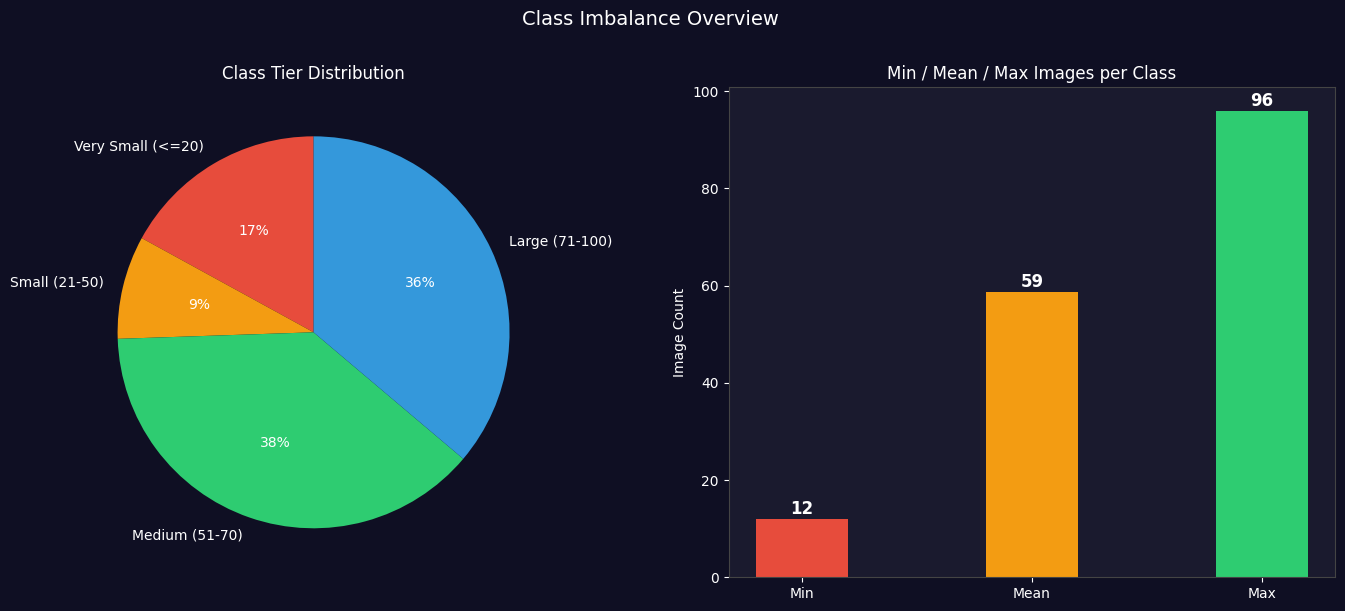

Tier breakdown:
  Very Small (<=20): 8 classes -> ['Sivasana', 'Alanasana', 'Navasana', 'Upavistha Konasana', 'Parsva Virabhadrasana', 'Ardha Navasana', 'Supta Kapotasana', 'Ashta Chandrasana']
  Small (21-50): 4 classes -> ['Parsvottanasana', 'Pincha Mayurasana', 'Hanumanasana', 'Trikonasana']
  Medium (51-70): 18 classes -> ['Utthita Parsvakonasana', 'Urdhva Mukha Svsnssana', 'Virabhadrasana Three', 'Vrksasana', 'Setu Bandha Sarvangasana', 'Phalakasana', 'Adho Mukha Vrksasana', 'Utthita Hasta Padangusthasana', 'Virabhadrasana One', 'Paschimottanasana', 'Salamba Bhujangasana', 'Camatkarasana', 'Virabhadrasana Two', 'Ardha Chandrasana', 'Marjaryasana', 'Ardha Pincha Mayurasana', 'Dhanurasana', 'Eka Pada Rajakapotasana']
  Large (71-100): 17 classes -> ['Ardha Matsyendrasana', 'Ustrasana', 'Bitilasana', 'Garudasana', 'Bakasana', 'Utkatasana', 'Baddha Konasana', 'Vasisthasana', 'Balasana', 'Padmasana', 'Urdhva Dhanurasana', 'Adho Mukha Svanasana', 'Salamba Sarvangasana', 'Malasana', 'Utt

In [4]:
counts_sorted = df.groupby('class').size().sort_values(ascending=False)
n = len(counts_sorted)

# Tier buckets
bins   = [0, 20, 50, 70, 100]
labels = ['Very Small (<=20)', 'Small (21-50)', 'Medium (51-70)', 'Large (71-100)']
bucket = pd.cut(counts_sorted, bins=bins, labels=labels)
tier_counts = bucket.value_counts().reindex(labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
wedge_colors = ['#e74c3c','#f39c12','#2ecc71','#3498db']
axes[0].pie(tier_counts, labels=labels, autopct='%1.0f%%',
            colors=wedge_colors, startangle=90,
            textprops={'color':'white', 'fontsize':10})
axes[0].set_title('Class Tier Distribution', fontsize=12)

# Imbalance bar: min vs max vs mean
cmin  = counts_sorted.min()
cmean = counts_sorted.mean()
cmax  = counts_sorted.max()
axes[1].bar(['Min','Mean','Max'], [cmin, cmean, cmax],
            color=['#e74c3c','#f39c12','#2ecc71'], width=0.4)
for i, v in enumerate([cmin, cmean, cmax]):
    axes[1].text(i, v+1, f'{v:.0f}', ha='center', fontsize=12, fontweight='bold')
axes[1].set_title('Min / Mean / Max Images per Class', fontsize=12)
axes[1].set_ylabel('Image Count')

plt.suptitle('Class Imbalance Overview', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('saved_models/ds_imbalance.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

print('Tier breakdown:')
for tier, cnt in tier_counts.items():
    classes_in_tier = counts_sorted[bucket == tier].index.tolist()
    print(f'  {tier}: {cnt} classes -> {classes_in_tier}')


## 4. Colour Mode Distribution


Colour modes found:
mode
RGB     2429
RGBA     281
P         42
LA         2
L          2


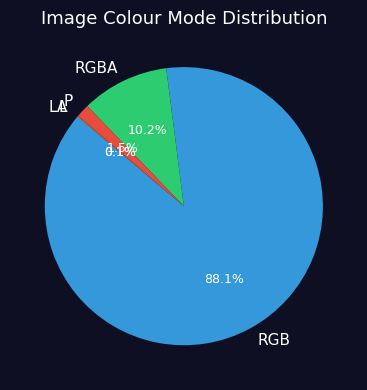


Images that are NOT RGB: 327 (11.9%)
Breakdown by class:
class                          mode
Adho Mukha Svanasana           RGBA    52
                               P        4
                               LA       1
Alanasana                      P        5
Ardha Navasana                 P        3
Ardha Pincha Mayurasana        P        2
Ashta Chandrasana              P        2
Baddha Konasana                RGBA    59
                               P        5
                               L        1
Bakasana                       P        1
Balasana                       RGBA    63
                               P        3
Bitilasana                     P        1
Dhanurasana                    P        1
Marjaryasana                   P        1
Padmasana                      RGBA    41
                               L        1
                               P        1
Pincha Mayurasana              RGBA     1
Setu Bandha Sarvangasana       P        1
                        

In [5]:
mode_counts = df['mode'].value_counts()
print('Colour modes found:')
print(mode_counts.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
colors  = ['#3498db','#2ecc71','#e74c3c','#9b59b6','#f39c12']
wedges, texts, autotexts = ax.pie(
    mode_counts, labels=mode_counts.index,
    autopct='%1.1f%%', colors=colors[:len(mode_counts)],
    startangle=140, textprops={'color':'white','fontsize':11})
for at in autotexts: at.set_fontsize(9)
ax.set_title('Image Colour Mode Distribution', fontsize=13)
plt.tight_layout()
plt.savefig('saved_models/ds_color_mode.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

# Classes with non-RGB images
non_rgb = df[df['mode'] != 'RGB']
print(f'\nImages that are NOT RGB: {len(non_rgb)} ({len(non_rgb)/len(df)*100:.1f}%)')
print('Breakdown by class:')
print(non_rgb.groupby('class')['mode'].value_counts().to_string())


## 5. Image Resolution & Aspect Ratio Analysis


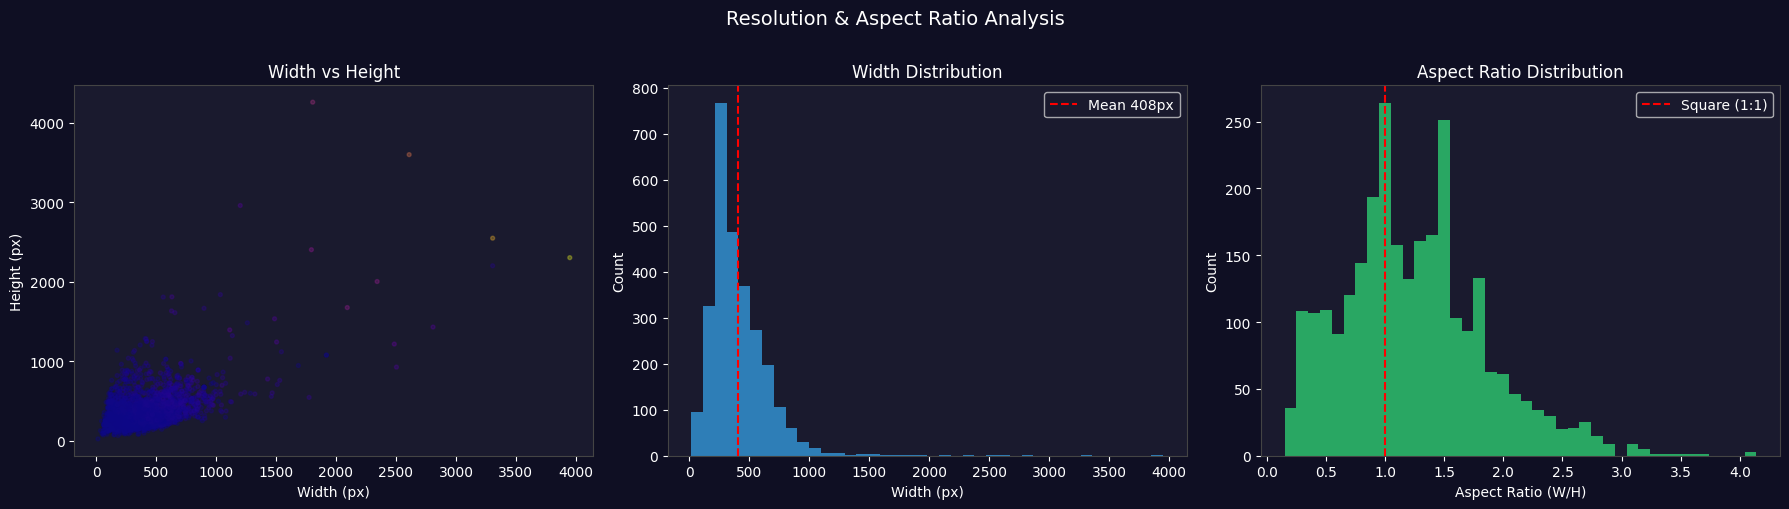

Width  : min=16 max=3949 mean=408
Height : min=26 max=4262 mean=370
Aspect : min=0.15 max=4.14 mean=1.24


In [6]:
df_valid = df[(df.width > 0) & (df.height > 0)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter: width vs height
axes[0].scatter(df_valid.width, df_valid.height, alpha=0.3, s=8,
                c=df_valid.size_kb, cmap='plasma')
axes[0].set_xlabel('Width (px)'); axes[0].set_ylabel('Height (px)')
axes[0].set_title('Width vs Height')

# Width histogram
axes[1].hist(df_valid.width,  bins=40, color='#3498db', alpha=0.8, edgecolor='none')
axes[1].axvline(df_valid.width.mean(), color='red', linestyle='--',
                label=f'Mean {df_valid.width.mean():.0f}px')
axes[1].set_xlabel('Width (px)'); axes[1].set_ylabel('Count')
axes[1].set_title('Width Distribution'); axes[1].legend()

# Aspect ratio histogram
aspects = df_valid.aspect.clip(0.1, 5)
axes[2].hist(aspects, bins=40, color='#2ecc71', alpha=0.8, edgecolor='none')
axes[2].axvline(1.0, color='red', linestyle='--', label='Square (1:1)')
axes[2].set_xlabel('Aspect Ratio (W/H)'); axes[2].set_ylabel('Count')
axes[2].set_title('Aspect Ratio Distribution'); axes[2].legend()

plt.suptitle('Resolution & Aspect Ratio Analysis', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('saved_models/ds_resolution.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

print(f'Width  : min={df_valid.width.min()} max={df_valid.width.max()} mean={df_valid.width.mean():.0f}')
print(f'Height : min={df_valid.height.min()} max={df_valid.height.max()} mean={df_valid.height.mean():.0f}')
print(f'Aspect : min={df_valid.aspect.min():.2f} max={df_valid.aspect.max():.2f} mean={df_valid.aspect.mean():.2f}')


## 6. File Size Distribution


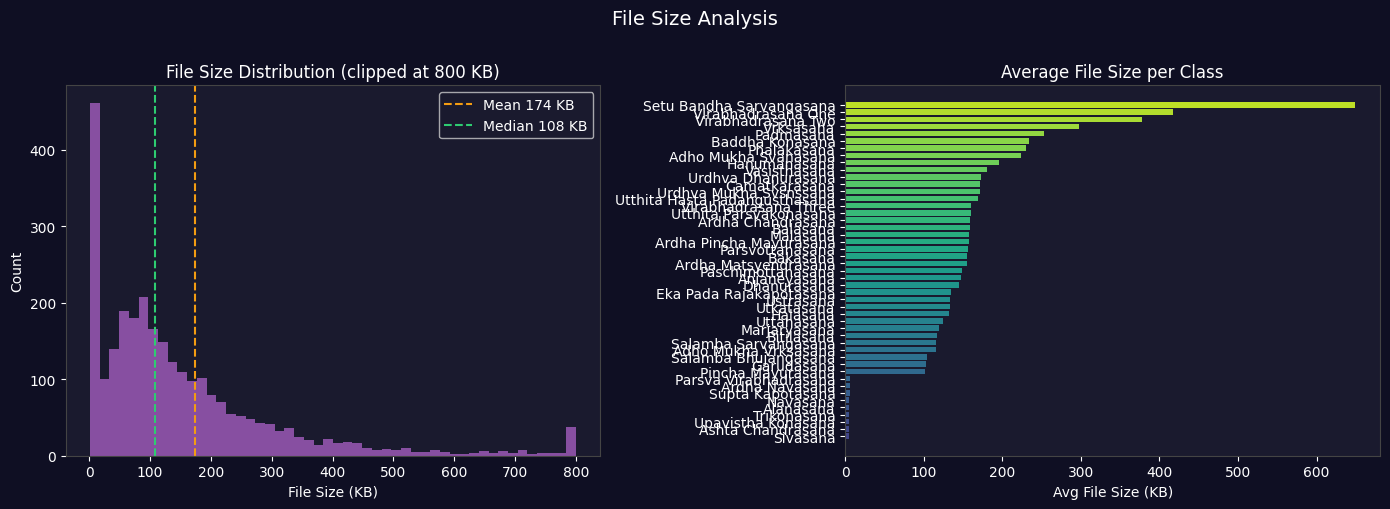

Mean   size: 174.1 KB
Median size: 107.6 KB
Max    size: 13103.2 KB  (Setu Bandha Sarvangasana)
Min    size: 1.3 KB  (Salamba Bhujangasana)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall histogram
axes[0].hist(df.size_kb.clip(0, 800), bins=50, color='#9b59b6', alpha=0.85, edgecolor='none')
axes[0].axvline(df.size_kb.mean(), color='#f39c12', linestyle='--',
                label=f'Mean {df.size_kb.mean():.0f} KB')
axes[0].axvline(df.size_kb.median(), color='#2ecc71', linestyle='--',
                label=f'Median {df.size_kb.median():.0f} KB')
axes[0].set_xlabel('File Size (KB)'); axes[0].set_ylabel('Count')
axes[0].set_title('File Size Distribution (clipped at 800 KB)')
axes[0].legend()

# Per-class avg size bar
avg_sz = df.groupby('class')['size_kb'].mean().sort_values(ascending=True)
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(avg_sz)))
axes[1].barh(avg_sz.index, avg_sz.values, color=colors, edgecolor='none', height=0.75)
axes[1].set_xlabel('Avg File Size (KB)')
axes[1].set_title('Average File Size per Class')

plt.suptitle('File Size Analysis', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('saved_models/ds_filesize.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

print(f'Mean   size: {df.size_kb.mean():.1f} KB')
print(f'Median size: {df.size_kb.median():.1f} KB')
print(f'Max    size: {df.size_kb.max():.1f} KB  ({df.loc[df.size_kb.idxmax(), "class"]})')
print(f'Min    size: {df.size_kb.min():.1f} KB  ({df.loc[df.size_kb.idxmin(), "class"]})')


## 7. Per-Class Average Width × Height Heatmap


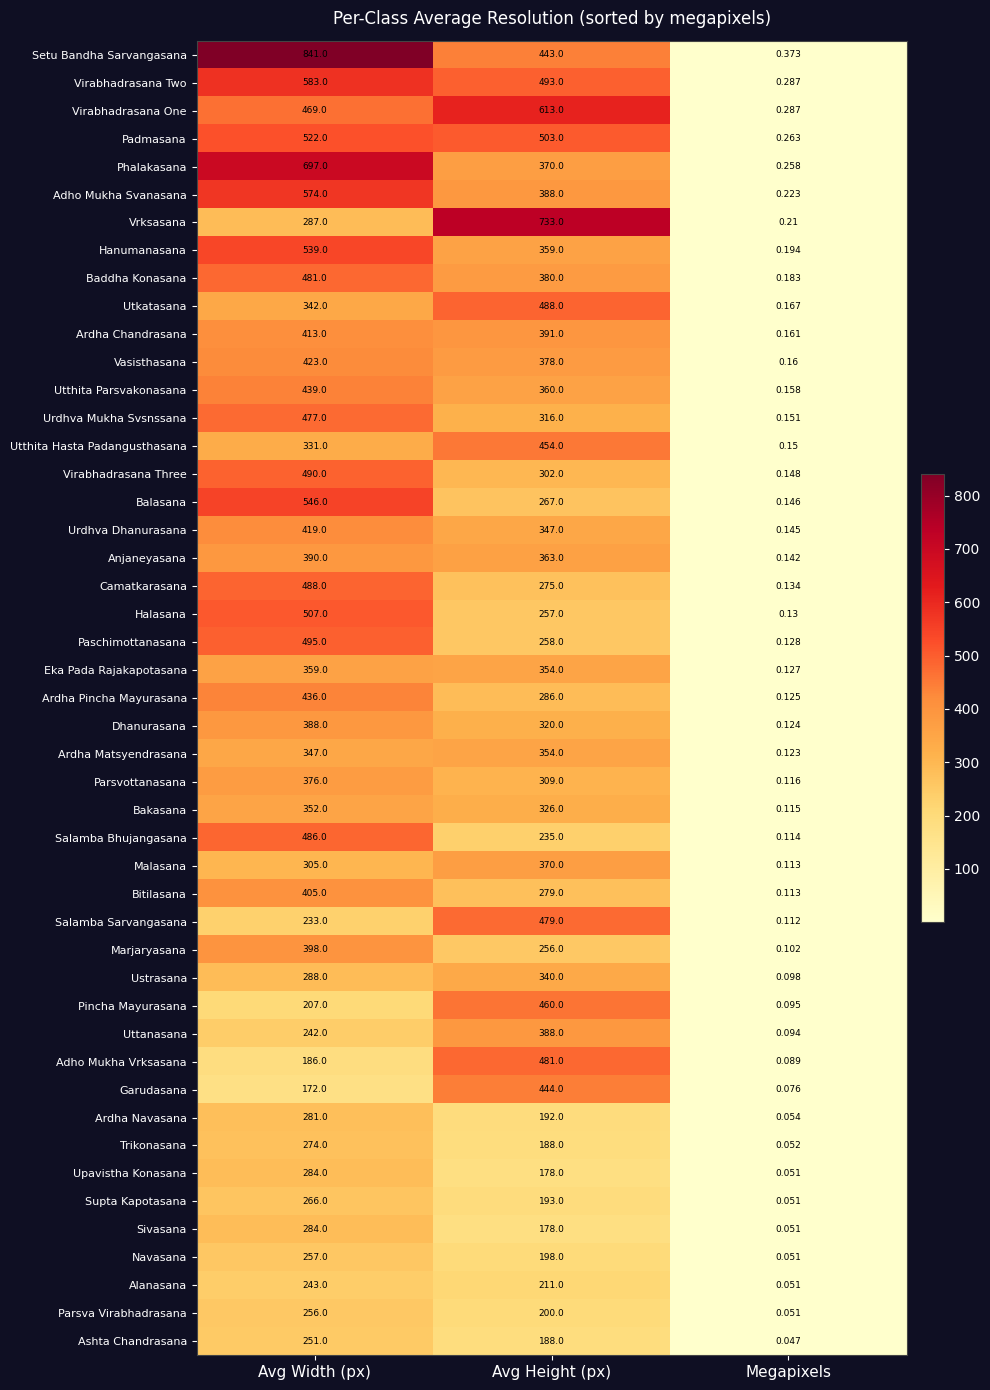

In [8]:
per_class_wh = df.groupby('class')[['width','height']].mean().round(0).astype(int)
per_class_wh['megapixels'] = (per_class_wh.width * per_class_wh.height / 1e6).round(3)
per_class_wh = per_class_wh.sort_values('megapixels', ascending=False)

fig, ax = plt.subplots(figsize=(10, 14))
data = per_class_wh[['width','height','megapixels']].values
im   = ax.imshow(data, cmap='YlOrRd', aspect='auto')
ax.set_xticks([0,1,2])
ax.set_xticklabels(['Avg Width (px)', 'Avg Height (px)', 'Megapixels'], fontsize=11)
ax.set_yticks(range(len(per_class_wh)))
ax.set_yticklabels(per_class_wh.index, fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
ax.set_title('Per-Class Average Resolution (sorted by megapixels)',
             fontsize=12, pad=12)
for i in range(len(per_class_wh)):
    for j, col in enumerate(['width','height','megapixels']):
        ax.text(j, i, str(per_class_wh.iloc[i][col]),
                ha='center', va='center', fontsize=6.5, color='black')
plt.tight_layout()
plt.savefig('saved_models/ds_resolution_heatmap.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()


## 8. Sample Image Grid — One Image per Class
Randomly samples one image from each of the 47 classes.


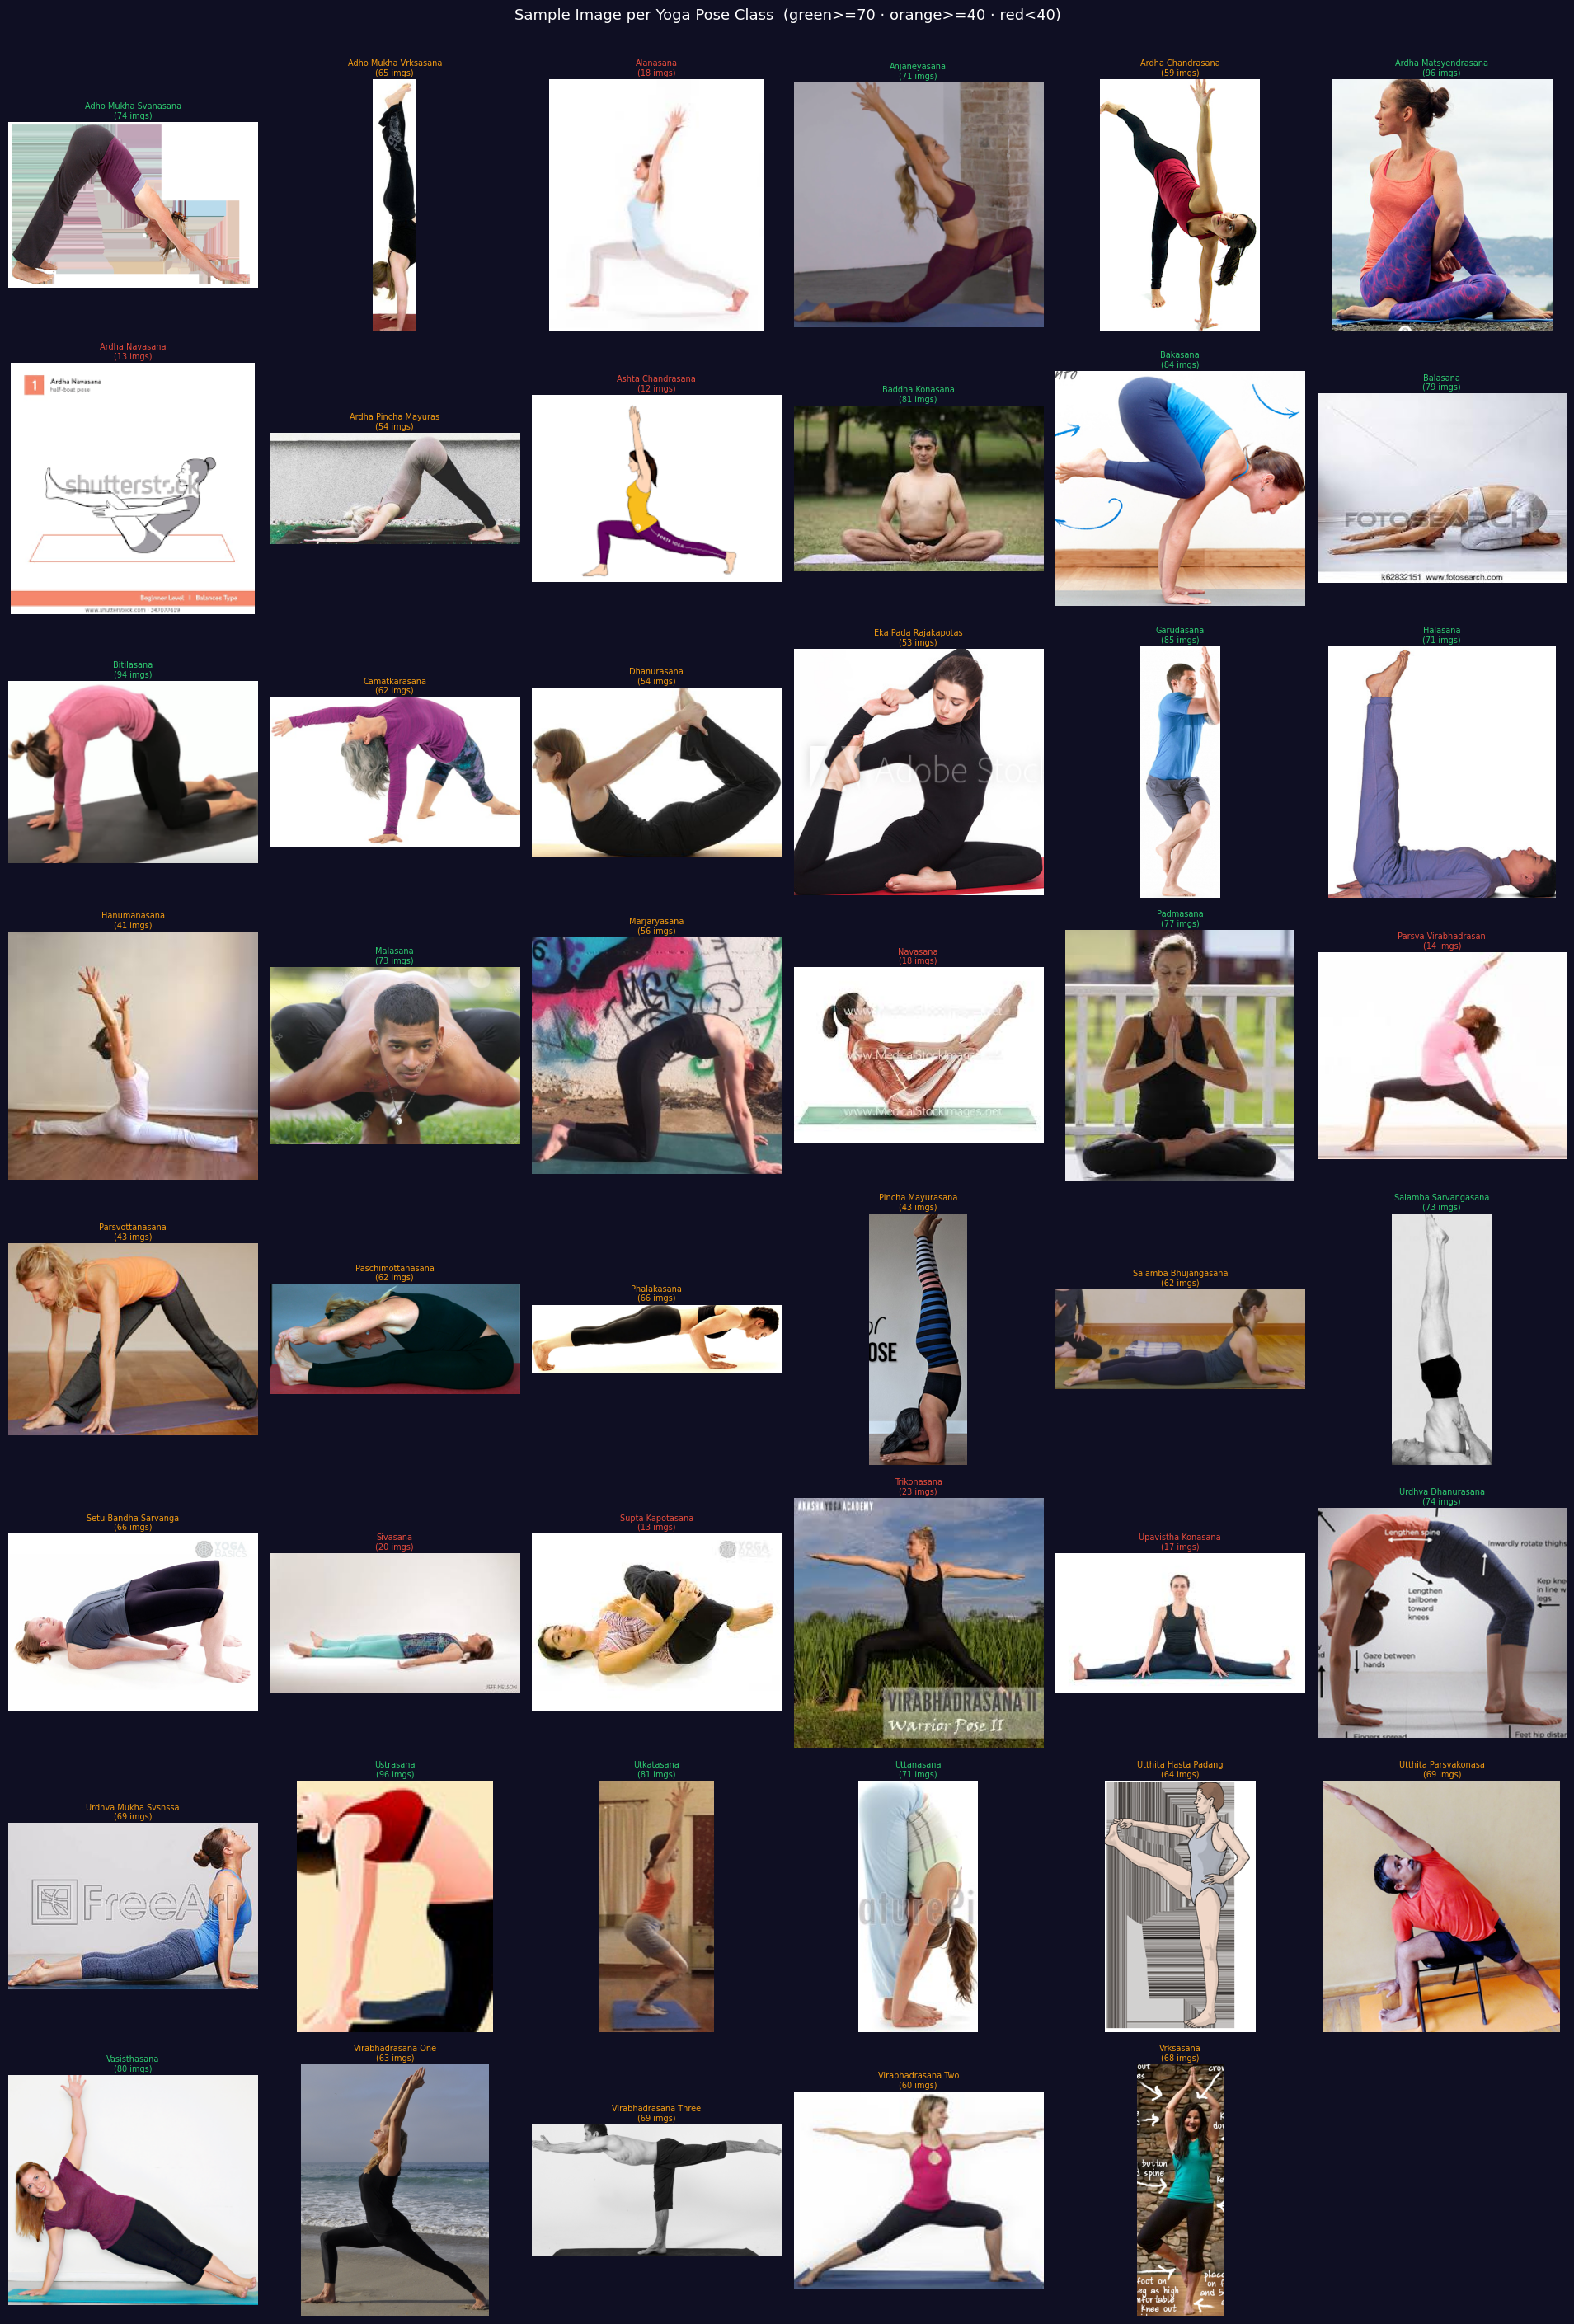

Saved -> saved_models/ds_sample_grid.png


In [9]:
import random
random.seed(42)
np.random.seed(42)

COLS = 6
ROWS = (NUM_CLASSES + COLS - 1) // COLS

fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS*3.2, ROWS*3.5))
fig.patch.set_facecolor('#0f0f23')
axes = axes.flatten()

for ax, cls in zip(axes, classes):
    cls_imgs = df[df['class'] == cls]['path'].tolist()
    img_path = random.choice(cls_imgs)
    try:
        img = Image.open(img_path).convert('RGB')
        ax.imshow(img)
    except:
        ax.set_facecolor('#333')
    n = len(cls_imgs)
    short = cls[:20]
    color = '#2ecc71' if n >= 70 else '#f39c12' if n >= 40 else '#e74c3c'
    ax.set_title(f'{short}\n({n} imgs)', fontsize=7, color=color, pad=3)
    ax.axis('off')

for ax in axes[NUM_CLASSES:]:
    ax.set_visible(False)

fig.suptitle('Sample Image per Yoga Pose Class  (green>=70 · orange>=40 · red<40)',
             fontsize=13, color='white', y=1.005)
plt.tight_layout()
plt.savefig('saved_models/ds_sample_grid.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved -> saved_models/ds_sample_grid.png')


## 9. Correlation: Image Count vs Avg Resolution vs Avg File Size


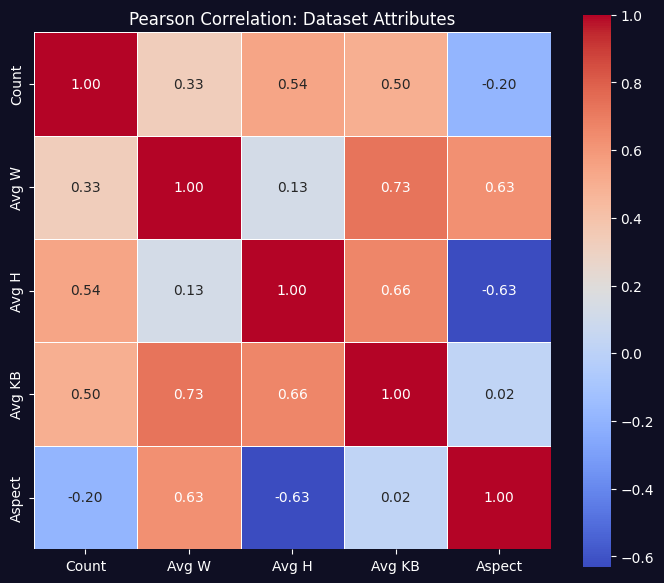

In [10]:
corr_df = df.groupby('class').agg(
    count    = ('path', 'count'),
    avg_w    = ('width', 'mean'),
    avg_h    = ('height', 'mean'),
    avg_kb   = ('size_kb', 'mean'),
    avg_asp  = ('aspect', 'mean'),
).round(1)

corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            ax=ax, linewidths=0.5, square=True,
            xticklabels=['Count','Avg W','Avg H','Avg KB','Aspect'],
            yticklabels=['Count','Avg W','Avg H','Avg KB','Aspect'])
ax.set_title('Pearson Correlation: Dataset Attributes', fontsize=12)
plt.tight_layout()
plt.savefig('saved_models/ds_correlation.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()


## 10. Dataset Summary Card


In [11]:
counts_all = df.groupby('class').size()

print('=' * 58)
print('        YOGA POSE DATASET — COMPLETE SUMMARY')
print('=' * 58)
print(f'  Total Images        : {len(df):,}')
print(f'  Pose Classes        : {NUM_CLASSES}')
print(f'  Total Dataset Size  : {df.size_kb.sum()/1024:.1f} MB')
print(f'  Mean Images/Class   : {counts_all.mean():.1f}')
print(f'  Median Images/Class : {counts_all.median():.0f}')
print(f'  Std Dev             : {counts_all.std():.1f}')
print(f'  Min (class)         : {counts_all.min()} ({counts_all.idxmin()})')
print(f'  Max (class)         : {counts_all.max()} ({counts_all.idxmax()})')
print(f'  Imbalance Ratio     : {counts_all.max()/counts_all.min():.1f}x')
print()
print('  Resolution:')
print(f'    Avg Width   : {df.width.mean():.0f} px')
print(f'    Avg Height  : {df.height.mean():.0f} px')
print(f'    Avg Aspect  : {df.aspect.mean():.2f}')
print()
print('  File Size:')
print(f'    Mean   : {df.size_kb.mean():.1f} KB')
print(f'    Median : {df.size_kb.median():.1f} KB')
print()
mode_pct = df.mode.value_counts(normalize=True)*100
print('  Colour Modes:')
for m, p in mode_pct.items():
    print(f'    {m:<8} : {p:.1f}%')
print()
print('  Class Tiers:')
print(f'    Very Small (<=20 imgs): {(counts_all<=20).sum()} classes')
print(f'    Small  (21-50  imgs)  : {((counts_all>20)&(counts_all<=50)).sum()} classes')
print(f'    Medium (51-70  imgs)  : {((counts_all>50)&(counts_all<=70)).sum()} classes')
print(f'    Large  (71-100 imgs)  : {(counts_all>70).sum()} classes')
print('=' * 58)


        YOGA POSE DATASET — COMPLETE SUMMARY
  Total Images        : 2,756
  Pose Classes        : 47
  Total Dataset Size  : 468.5 MB
  Mean Images/Class   : 58.6
  Median Images/Class : 65
  Std Dev             : 24.0
  Min (class)         : 12 (Ashta Chandrasana)
  Max (class)         : 96 (Ardha Matsyendrasana)
  Imbalance Ratio     : 8.0x

  Resolution:
    Avg Width   : 408 px
    Avg Height  : 370 px
    Avg Aspect  : 1.24

  File Size:
    Mean   : 174.1 KB
    Median : 107.6 KB



AttributeError: 'function' object has no attribute 'value_counts'

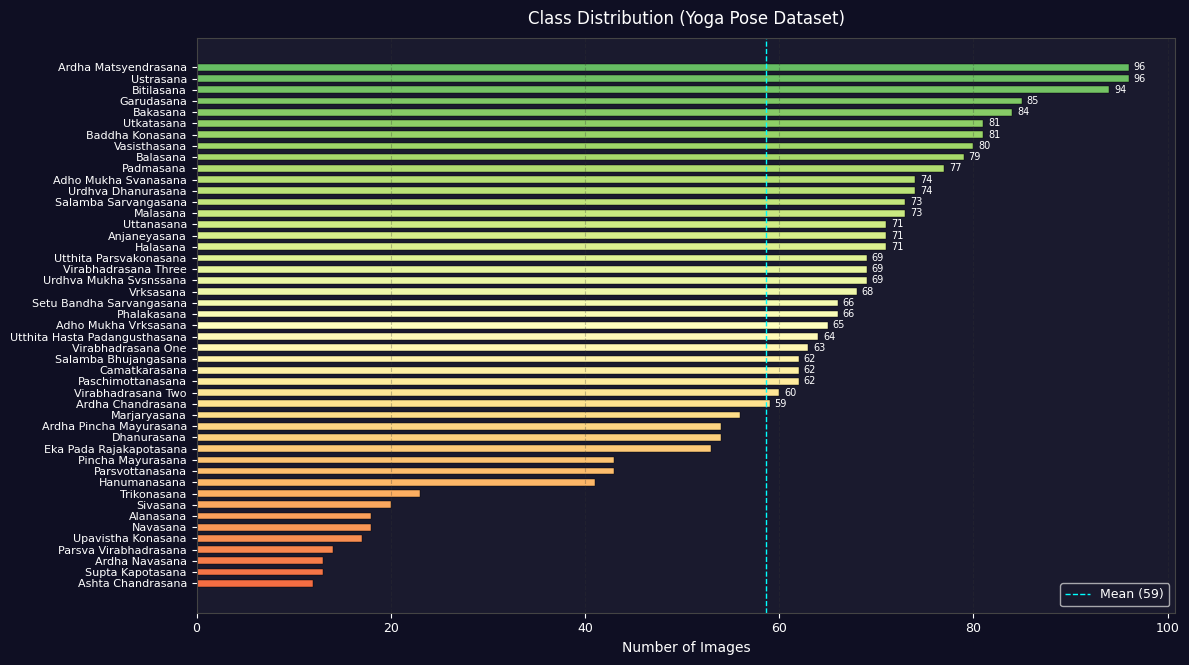

In [12]:
counts = df.groupby('class').size().sort_values(ascending=True)

import numpy as np
import matplotlib.pyplot as plt

# Color gradient
colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(counts)))

# 16:9 aspect ratio
fig, ax = plt.subplots(figsize=(12, 6.75))  # 16:9

bars = ax.barh(
    counts.index,
    counts.values,
    color=colors,
    edgecolor='black',
    linewidth=0.3,
    height=0.6
)

# Labels and title (compact)
ax.set_xlabel('Number of Images', fontsize=10)
ax.set_title('Class Distribution (Yoga Pose Dataset)', fontsize=12, pad=10)

# Mean line
avg = counts.mean()
ax.axvline(avg, color='cyan', linestyle='--', linewidth=1, label=f'Mean ({avg:.0f})')
ax.legend(fontsize=9)

# Reduce tick clutter
ax.tick_params(axis='y', labelsize=8)
ax.tick_params(axis='x', labelsize=9)

# Annotate only important bars (avoid clutter)
for bar, val in zip(bars, counts.values):
    if val > avg:  # show only above-average labels
        ax.text(val + 0.5,
                bar.get_y() + bar.get_height()/2,
                str(val),
                va='center',
                fontsize=7)

# Grid (light)
ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

# Save
plt.savefig(
    'saved_models/ds_class_distribution_16_9.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()